In [1]:
from pathlib import Path

print("Running Model 1 locally.")

Running Model 1 locally.


In [2]:

from pathlib import Path

DATASET_DIR = Path(
    r"C:\Users\dev20\OneDrive\Desktop\THE END\MLP\GaitTensors1"
)

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_DIR}"
    )

print("Dataset found:", DATASET_DIR)


Dataset found: C:\Users\dev20\OneDrive\Desktop\THE END\MLP\GaitTensors1


In [3]:

TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "validation"
TEST_DIR = DATASET_DIR / "test"

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print(f"{folder.name} exists:", folder.exists())

    if not folder.exists():
        raise FileNotFoundError(
            f"Missing folder: {folder}"
        )


train exists: True
validation exists: True
test exists: True


In [4]:
CLASSES = ['Regular', 'Limping', 'Shuffling']

for split_name, split_dir in [
    ('Training', TRAIN_DIR),
    ('Validation', VAL_DIR),
    ('Testing', TEST_DIR)
]:
    print(f"\n{split_name}:")

    if not split_dir.exists():
        print("ERROR: Folder not found:", split_dir)
        continue

    for class_name in CLASSES:
        class_dir = split_dir / class_name
        count = len(list(class_dir.glob('*.pt'))) if class_dir.exists() else 0
        print(f"  {class_name}: {count} tensors")


Training:
  Regular: 199 tensors
  Limping: 200 tensors
  Shuffling: 200 tensors

Validation:
  Regular: 50 tensors
  Limping: 50 tensors
  Shuffling: 50 tensors

Testing:
  Regular: 51 tensors
  Limping: 49 tensors
  Shuffling: 49 tensors


In [5]:
train_files = [
    path
    for class_name in CLASSES
    for path in sorted((TRAIN_DIR / class_name).glob('*.pt'))
]

val_files = [
    path
    for class_name in CLASSES
    for path in sorted((VAL_DIR / class_name).glob('*.pt'))
]

test_files = [
    path
    for class_name in CLASSES
    for path in sorted((TEST_DIR / class_name).glob('*.pt'))
]

print("Training videos:", len(train_files))
print("Validation videos:", len(val_files))
print("Testing videos:", len(test_files))

Training videos: 599
Validation videos: 150
Testing videos: 149


In [6]:
import torch
from torch.utils.data import Dataset, DataLoader

# Class labels
CLASSES = ["Regular", "Limping", "Shuffling"]

CLASS_TO_IDX = {
    "Regular": 0,
    "Limping": 1,
    "Shuffling": 2
}

class GaitTensorDataset(Dataset):

    def __init__(self, files):
        self.files = files

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path = self.files[idx]

        # Determine label from the parent folder
        class_name = path.parent.name
        label = CLASS_TO_IDX[class_name]

        # Load the preprocessed tensor
        frames = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        # Verify tensor shape
        if frames.shape != (3, 32, 256, 256):
            raise ValueError(
                f"Unexpected shape in {path}: {frames.shape}"
            )

        if not torch.isfinite(frames).all():
            raise ValueError(
                f"Non-finite values found in {path}"
            )

        return frames.float(), label


# Create datasets
train_dataset = GaitTensorDataset(train_files)
val_dataset = GaitTensorDataset(val_files)
test_dataset = GaitTensorDataset(test_files)

# Batch size
BATCH_SIZE = 2

# Reproducibility
SEED = 42
generator = torch.Generator()
generator.manual_seed(SEED)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=generator,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 300
Validation batches: 75
Testing batches: 75


In [7]:
frames, labels = next(iter(train_loader))

print("Batch tensor shape:", frames.shape)
print("Batch labels:", labels)
print("Tensor dtype:", frames.dtype)
print("All values finite:", torch.isfinite(frames).all().item())

Batch tensor shape: torch.Size([2, 3, 32, 256, 256])
Batch labels: tensor([1, 2])
Tensor dtype: torch.float32
All values finite: True


In [8]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ), "GB")
else:
    print("GPU not detected. Check your PyTorch CUDA installation.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU name: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.0 GB


In [9]:
import torch
import torch.nn as nn
from pytorchvideo.models.hub import slowfast_r50

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained SlowFast-R50
model = slowfast_r50(pretrained=True)

# Freeze pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# Replace the final classification layer
old_head = model.blocks[-1].proj

model.blocks[-1].proj = nn.Linear(
    old_head.in_features,
    len(CLASSES)
)


# =====================================================================
# CORRECT FOR EXPERIMENT 4: Unfreeze the ENTIRE network completely
# =====================================================================
for param in model.parameters():
    param.requires_grad = True
# =====================================================================

# Move model to GPU
model = model.to(device)

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print("\nTrainable layers:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.numel())

print("Model device:", next(model.parameters()).device)


c:\Users\dev20\OneDrive\Desktop\THE END\MLP\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Total parameters: 33,651,403
Trainable parameters: 33,651,403

Trainable layers:
blocks.0.multipathway_blocks.0.conv.weight 9408
blocks.0.multipathway_blocks.0.norm.weight 64
blocks.0.multipathway_blocks.0.norm.bias 64
blocks.0.multipathway_blocks.1.conv.weight 5880
blocks.0.multipathway_blocks.1.norm.weight 8
blocks.0.multipathway_blocks.1.norm.bias 8
blocks.0.multipathway_fusion.conv_fast_to_slow.weight 896
blocks.0.multipathway_fusion.norm.weight 16
blocks.0.multipathway_fusion.norm.bias 16
blocks.1.multipathway_blocks.0.res_blocks.0.branch1_conv.weight 20480
blocks.1.multipathway_blocks.0.res_blocks.0.branch1_norm.weight 256
blocks.1.multipathway_blocks.0.res_blocks.0.branch1_norm.bias 256
blocks.1.multipathway_blocks.0.res_blocks.0.branch2.conv_a.weight 5120
blocks.1.multipathway_blocks.0.res_blocks.0.branch2.norm_a.weight 64
blocks.1.multipathway_blocks.0.res_blocks.0.branch2.norm_a.bias 64
blocks.1.multipathway_blocks.0.res_bl

In [10]:
from collections import Counter

train_labels = [
    CLASS_TO_IDX[path.parent.name]
    for path in train_files
]

print("Training class distribution:")
for class_name, label in CLASS_TO_IDX.items():
    print(
        f"{class_name}: "
        f"{Counter(train_labels).get(label, 0)} videos"
    )


Training class distribution:
Regular: 199 videos
Limping: 200 videos
Shuffling: 200 videos


In [11]:
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

# =====================================================================
# CORRECTED FOR EXPERIMENT 4: Extract ALL active parameters across the entire network
# =====================================================================
trainable_parameters = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
# =====================================================================

# Three-class classification loss (Kept constant)
criterion = nn.CrossEntropyLoss()

print("Optimizer: AdamW (Full Fine-Tuning)")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Loss function: CrossEntropyLoss")

# Updated print logs to verify the Full Fine-Tuning structure
print("\n--- Tuning Targets (Experiment 4) ---")
print("Are ALL model parameters trainable?:", all(p.requires_grad for p in model.parameters()))
print("Total parameters in optimizer:", sum(
    p.numel() for p in trainable_parameters
))

Optimizer: AdamW (Full Fine-Tuning)
Learning rate: 1e-05
Weight decay: 0.0001
Loss function: CrossEntropyLoss

--- Tuning Targets (Experiment 4) ---
Are ALL model parameters trainable?: True
Total parameters in optimizer: 33651403


In [12]:
import time
import csv
import torch
import matplotlib.pyplot as plt
from pathlib import Path

MAX_EPOCHS = 20
PATIENCE = 6

# Save outputs locally in your MLP project folder
OUTPUT_DIR = Path.cwd() / "SlowFast_Experiment4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = OUTPUT_DIR / "best_model.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
LOSS_PLOT_PATH = OUTPUT_DIR / "training_vs_validation_loss.png"

# Mixed precision for CUDA
use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("Device:", device)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Mixed precision:", use_amp)
print("Output folder:", OUTPUT_DIR.resolve())


Device: cuda
Maximum epochs: 20
Early stopping patience: 6
Mixed precision: True
Output folder: C:\Users\dev20\OneDrive\Desktop\THE END\MLP\SlowFast_Experiment4


In [13]:
def create_slowfast_inputs(frames):
    # frames: [B, C, T, H, W]
    num_frames = frames.shape[2]

    indices = torch.linspace(
        0,
        num_frames - 1,
        steps=num_frames // 4,
        device=frames.device
    ).long()

    slow_pathway = torch.index_select(
        frames, 2, indices
    )

    fast_pathway = frames

    return [slow_pathway, fast_pathway]


# Verify the input shapes
sample_frames, sample_labels = next(iter(train_loader))
sample_frames = sample_frames.to(device)

slow, fast = create_slowfast_inputs(sample_frames)

print("Slow pathway:", slow.shape)
print("Fast pathway:", fast.shape)

del sample_frames, sample_labels, slow, fast

Slow pathway: torch.Size([2, 3, 8, 256, 256])
Fast pathway: torch.Size([2, 3, 32, 256, 256])


In [14]:
def run_epoch(loader, training):
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    # =====================================================================
    # CORRECTED FOR EXPERIMENT 4: Set the entire network mode seamlessly
    # =====================================================================
    if training:
        model.train()  # Automatically sets EVERY block (0 to 6) to training mode
    else:
        model.eval()   # Automatically sets EVERY block to evaluation mode
    # =====================================================================

    for frames, labels in loader:
        # Move tensors to GPU asynchronously alongside your pin_memory configuration
        frames = frames.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Structure input data into the custom [slow, fast] list structure
        inputs = create_slowfast_inputs(frames)

        if training:
            optimizer.zero_grad(set_to_none=True)

        # Control backpropagation tracking engine based on execution phase
        with torch.set_grad_enabled(training):
            # Implement Automatic Mixed Precision (AMP) to optimize VRAM footprint
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            if training:
                # Scaler handles 16-bit decimal underflow protection
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        # Aggregate training metrics accurately even if final batch is smaller
        batch_count = labels.size(0)
        total_loss += loss.item() * batch_count
        total_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        total_samples += batch_count

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [15]:
history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.time()

    # Training pass
    train_loss, train_acc = run_epoch(
        train_loader,
        training=True
    )

    # Validation pass
    val_loss, val_acc = run_epoch(
        val_loader,
        training=False
    )

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    # Save history after every epoch
    with open(HISTORY_PATH, "w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(history.keys())

        for row in zip(*history.values()):
            writer.writerow(row)

    # Save the best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "class_to_idx": CLASS_TO_IDX
            },
            BEST_MODEL_PATH
        )
    else:
        epochs_without_improvement += 1

    elapsed = (time.time() - epoch_start) / 60

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val acc: {val_acc:.4f} | "
        f"Time: {elapsed:.2f} min"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}."
        )
        print(f"Best epoch: {best_epoch}")
        break

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Total time: {(time.time() - start_time) / 60:.2f} minutes")
print("Best checkpoint:", BEST_MODEL_PATH)

Epoch 01/20 | Train loss: 0.8490 | Val loss: 0.5019 | Train acc: 0.6494 | Val acc: 0.8200 | Time: 14.54 min
Epoch 02/20 | Train loss: 0.2979 | Val loss: 0.1963 | Train acc: 0.9432 | Val acc: 0.9667 | Time: 14.88 min
Epoch 03/20 | Train loss: 0.1234 | Val loss: 0.0881 | Train acc: 0.9783 | Val acc: 1.0000 | Time: 14.42 min
Epoch 04/20 | Train loss: 0.0428 | Val loss: 0.1811 | Train acc: 1.0000 | Val acc: 0.9333 | Time: 14.72 min
Epoch 05/20 | Train loss: 0.0299 | Val loss: 0.1120 | Train acc: 0.9967 | Val acc: 0.9867 | Time: 14.71 min
Epoch 06/20 | Train loss: 0.0163 | Val loss: 0.1098 | Train acc: 1.0000 | Val acc: 0.9800 | Time: 14.70 min
Epoch 07/20 | Train loss: 0.0122 | Val loss: 0.0932 | Train acc: 1.0000 | Val acc: 0.9800 | Time: 14.73 min
Epoch 08/20 | Train loss: 0.0081 | Val loss: 0.1050 | Train acc: 1.0000 | Val acc: 0.9667 | Time: 14.68 min
Epoch 09/20 | Train loss: 0.0061 | Val loss: 0.0536 | Train acc: 1.0000 | Val acc: 0.9867 | Time: 14.69 min
Epoch 10/20 | Train loss: 0.

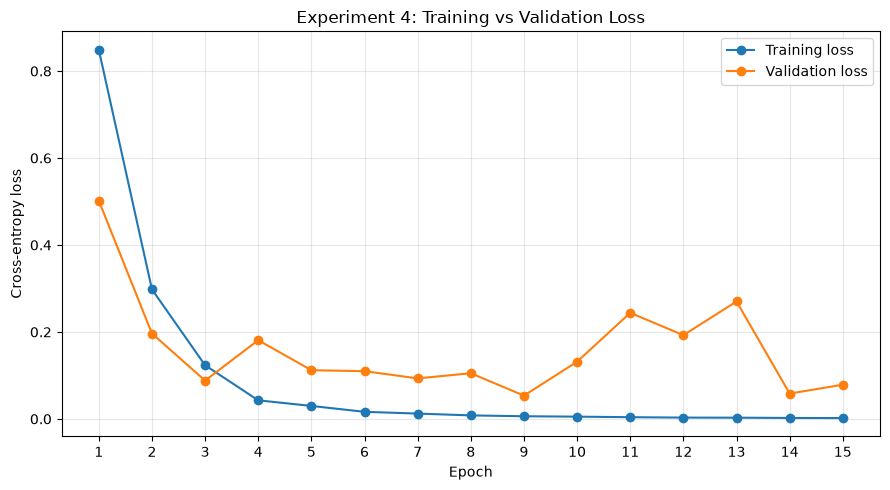

Loss curve saved to: c:\Users\dev20\OneDrive\Desktop\THE END\MLP\SlowFast_Experiment4\training_vs_validation_loss.png
Training history saved to: c:\Users\dev20\OneDrive\Desktop\THE END\MLP\SlowFast_Experiment4\training_history.csv


In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    marker="o",
    label="Training loss"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    marker="o",
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Experiment 4: Training vs Validation Loss")
plt.xticks(history["epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    LOSS_PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Loss curve saved to:", LOSS_PLOT_PATH)
print("Training history saved to:", HISTORY_PATH)

In [17]:
import sklearn
print(sklearn.__version__)

1.9.1


Checkpoint epoch: 9
Best validation loss: 0.0536

========== TEST RESULTS ==========
Test samples:       149
Test loss:          0.2124
Test accuracy:      0.9530 (95.30%)
Macro precision:    0.9583
Macro recall:       0.9537
Macro F1-score:     0.9537

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

     Regular     1.0000    0.9020    0.9485        51
     Limping     0.8750    1.0000    0.9333        49
   Shuffling     1.0000    0.9592    0.9792        49

    accuracy                         0.9530       149
   macro avg     0.9583    0.9537    0.9537       149
weighted avg     0.9589    0.9530    0.9536       149



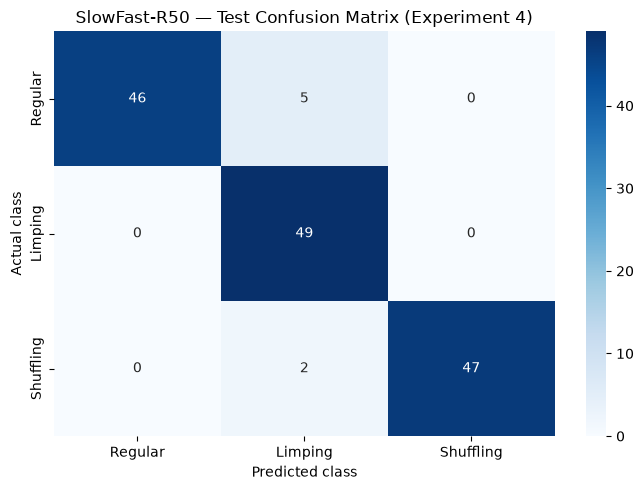

In [18]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. Load the best trained checkpoint
# --------------------------------------------------
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Checkpoint epoch:", checkpoint["epoch"])
print(f"Best validation loss: {checkpoint['best_val_loss']:.4f}")

# --------------------------------------------------
# 2. Test the model
# --------------------------------------------------
criterion = nn.CrossEntropyLoss()

all_labels = []
all_predictions = []
total_loss = 0.0
total_samples = 0

with torch.no_grad():
    for frames, labels in test_loader:
        frames = frames.to(device)
        labels = labels.to(device)

        # Use the same pathway function as training
        slow, fast = create_slowfast_inputs(frames)

        outputs = model([slow, fast])
        loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# --------------------------------------------------
# 3. Calculate test metrics
# --------------------------------------------------
if total_samples == 0:
    raise ValueError("Test dataset contains no samples.")
test_loss = total_loss / total_samples


accuracy = accuracy_score(
    all_labels, all_predictions
)

precision = precision_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

recall = recall_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

f1 = f1_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

print("\n========== TEST RESULTS ==========")
print(f"Test samples:       {total_samples}")
print(f"Test loss:          {test_loss:.4f}")
print(f"Test accuracy:      {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision:    {precision:.4f}")
print(f"Macro recall:       {recall:.4f}")
print(f"Macro F1-score:     {f1:.4f}")

# --------------------------------------------------
# 4. Per-class performance
# --------------------------------------------------
idx_to_class = {
    index: name
    for name, index in CLASS_TO_IDX.items()
}

class_names = [
    idx_to_class[i]
    for i in range(len(idx_to_class))
]

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# --------------------------------------------------
# 5. Confusion matrix
# --------------------------------------------------
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("SlowFast-R50 — Test Confusion Matrix (Experiment 4)")
plt.tight_layout()
plt.show()

In [19]:
print("Model class mapping:", CLASS_TO_IDX)

print("\nTraining dataset mapping:")
print(train_dataset.class_to_idx if hasattr(train_dataset, "class_to_idx") else "Not exposed")

print("\nValidation dataset mapping:")
print(val_dataset.class_to_idx if hasattr(val_dataset, "class_to_idx") else "Not exposed")

print("\nTest dataset mapping:")
print(test_dataset.class_to_idx if hasattr(test_dataset, "class_to_idx") else "Not exposed")

Model class mapping: {'Regular': 0, 'Limping': 1, 'Shuffling': 2}

Training dataset mapping:
Not exposed

Validation dataset mapping:
Not exposed

Test dataset mapping:
Not exposed


In [20]:
from collections import Counter

def inspect_loader(loader, name):
    counts = Counter()

    for _, labels in loader:
        counts.update(labels.tolist())

    print(f"\n{name}:")
    for idx, class_name in enumerate(
        ["Regular", "Limping", "Shuffling"]
    ):
        print(f"{class_name} (label {idx}): {counts[idx]}")

inspect_loader(train_loader, "Training")
inspect_loader(val_loader, "Validation")
inspect_loader(test_loader, "Testing")


Training:
Regular (label 0): 199
Limping (label 1): 200
Shuffling (label 2): 200

Validation:
Regular (label 0): 50
Limping (label 1): 50
Shuffling (label 2): 50

Testing:
Regular (label 0): 51
Limping (label 1): 49
Shuffling (label 2): 49


In [21]:

from collections import Counter
import torch

# Load the best checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_labels = []
all_predictions = []

# Run inference only — no training
with torch.no_grad():
    for frames, labels in test_loader:
        frames = frames.to(device)

        slow, fast = create_slowfast_inputs(frames)
        outputs = model([slow, fast])
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

# Count predictions
pred_counts = Counter(all_predictions)

class_names = ["Regular", "Limping", "Shuffling"]

print("Predicted class counts:")
for idx, name in enumerate(class_names):
    print(f"{name}: {pred_counts[idx]}")

# Save results for further analysis
test_results = {
    "labels": all_labels,
    "predictions": all_predictions
}

Predicted class counts:
Regular: 46
Limping: 56
Shuffling: 47
